# Задание 2.7

(С использованием «Jupyter Notebook») Обобщение биномиальных коэффициентов. Напомним, $C_n^k=\dfrac{n!}{k!\,(n-k)!}$. Вспомним, что $n!=\Gamma(n+1)$, где

$$
\Gamma(z)=\int_0^{\infty}x^{z-1}e^{-x}\,dx,\qquad \operatorname{Re}(z)>0 .
$$

Определим формально символ $C_z^w$ для $z,w\in\mathbb{C}$:

$$
C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)} .
$$

**a)** Найдите $C_{1+i}^{1-i}$. *Ответ:* $4.36745+4.85163i$.

**b)** Найдите $\operatorname{Arg}\bigl(C_{1+i}^{1-i}\bigr)$. *Ответ:* $0.837869$ $(48.0064^\circ)$.

**c)** Постройте линии уровня $\operatorname{Arg}\bigl[C_z^{1/z}\bigr]=const$, где $z=x+iy$.

## Теория

**Гамма-функция.** Интеграл Эйлера определяет $\Gamma(z)$ при $\operatorname{Re}z>0$; с помощью соотношения $\Gamma(z+1)=z\,\Gamma(z)$ она аналитически продолжается на всю плоскость, кроме простых полюсов в точках $z=0,-1,-2,\dots$ Нулей у $\Gamma(z)$ нет. Для натуральных $n$ выполняется $\Gamma(n+1)=n!$, поэтому формула

$$
C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}
$$

при целых $z=n$, $w=k$ даёт обычный биномиальный коэффициент, а при комплексных — его обобщение. В `scipy.special.gamma` гамма-функция реализована и для комплексного аргумента.

**a), b)** Подставляем $z=1+i$ (нижний индекс) и $w=1-i$ (верхний индекс):

$$
C_{1+i}^{1-i}=\frac{\Gamma(2+i)}{\Gamma(2-i)\,\Gamma(1+2i)},\qquad \operatorname{Arg}C=\operatorname{arctg}\frac{\operatorname{Im}C}{\operatorname{Re}C}\ \ (\operatorname{Re}C>0).
$$

**c)** При $w=1/z$:

$$
f(z)=C_z^{1/z}=\frac{\Gamma(z+1)}{\Gamma\!\left(\frac1z+1\right)\Gamma\!\left(z-\frac1z+1\right)} .
$$

Вблизи $z=0$ аргумент $1/z$ огромен, и $\Gamma$ переполняет разрядную сетку. Поэтому считаем через **логарифм гамма-функции** (`scipy.special.loggamma`):

$$
\ln f=\ln\Gamma(z+1)-\ln\Gamma\!\left(\tfrac1z+1\right)-\ln\Gamma\!\left(z-\tfrac1z+1\right),\qquad \operatorname{Arg}f=\operatorname{Im}\ln f\ \ (\mathrm{mod}\ 2\pi),
$$

после чего приводим значение к главному промежутку $(-\pi,\pi]$.

Линии уровня $\operatorname{Arg}f=\theta$ — это линии, на которых $f(z)$ лежит на луче $\arg w=\theta$. Все они сходятся в нулях и полюсах $f$. Нули $f$ порождаются полюсами гамма-функций в знаменателе ($\frac1z+1=-m$ или $z-\frac1z+1=-m$, $m=0,1,2,\dots$): они лежат на действительной оси и сгущаются к точке $z=0$, где у функции существенная особенность. По формуле дополнения $\Gamma(1+u)\Gamma(1-u)=\dfrac{\pi u}{\sin\pi u}$ при малых $z$ имеем $f(z)\approx\dfrac{\sin(\pi/z)}{\pi/z}$, поэтому картинка вблизи нуля почти симметрична.

Функция $\operatorname{Arg}$ разрывна на линии, где $f(z)<0$ (скачок с $\pi$ на $-\pi$), и обычный `contour` нарисовал бы там пучок ложных линий. Поэтому линию $\operatorname{Arg}f=\theta$ строим как нулевую линию уровня $\sin(\operatorname{Arg}f-\theta)$ в области, где $\cos(\operatorname{Arg}f-\theta)>0$.

a) C = 4.36745 + 4.85163i
b) Arg C = 0.837869 рад = 48.0064°


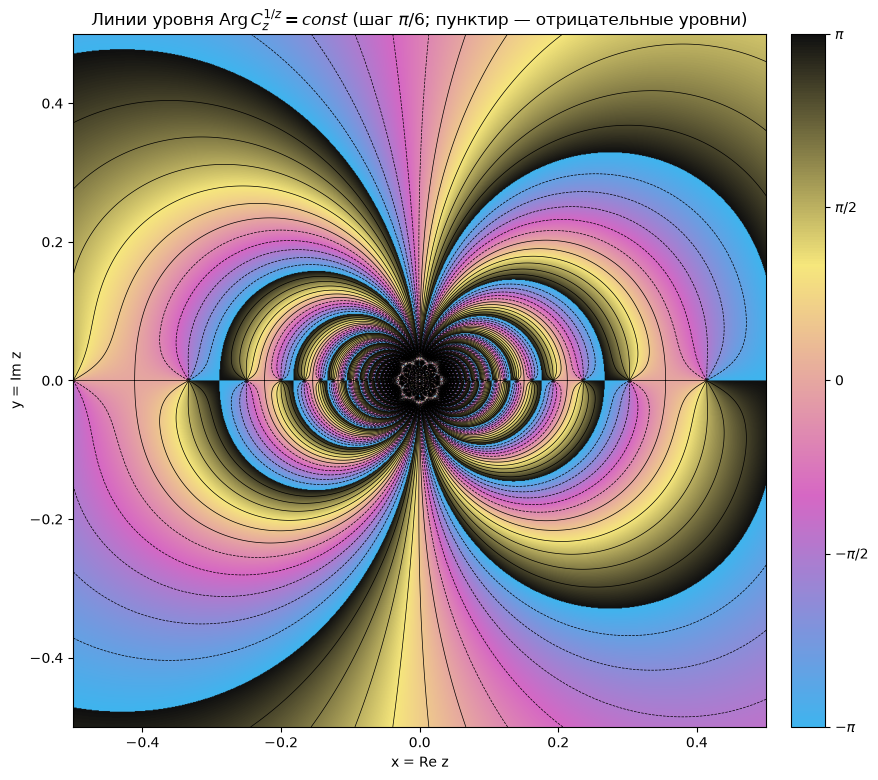

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import gamma, loggamma


def binom(z, w):
    """Обобщённый биномиальный коэффициент C_z^w = Г(z+1) / (Г(w+1)·Г(z-w+1))."""
    return gamma(z + 1) / (gamma(w + 1) * gamma(z - w + 1))


# ---------- a) значение C_{1+i}^{1-i} ----------
C = binom(1 + 1j, 1 - 1j)
print(f"a) C = {C.real:.5f} + {C.imag:.5f}i")

# ---------- b) аргумент (главное значение) ----------
arg = np.angle(C)
print(f"b) Arg C = {arg:.6f} рад = {np.degrees(arg):.4f}°")

# ---------- c) линии уровня Arg C_z^{1/z} ----------
L = 0.5                                   # рисуем квадрат [-L, L] × [-L, L]
x = np.linspace(-L, L, 1000)              # чётное число узлов: точка z = 0 в сетку не попадает
X, Y = np.meshgrid(x, x)
Z = X + 1j*Y

# ln C_z^{1/z} через логарифм гамма-функции (сама Г(1/z + 1) около нуля переполняется)
logC = loggamma(Z + 1) - loggamma(1/Z + 1) - loggamma(Z - 1/Z + 1)
# Arg = Im ln C, приведённая к промежутку (-π, π]
Arg = np.angle(np.exp(1j*logC.imag))

# Цветовая шкала: -π (голубой) -> розовый -> жёлтый -> +π (чёрный)
cmap = LinearSegmentedColormap.from_list("cmyk", ["#3fb4ee", "#d667c4", "#f6e77c", "#101010"])

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(Arg, cmap=cmap, extent=[-L, L, -L, L], origin='lower', vmin=-np.pi, vmax=np.pi)

# Линии уровня Arg = θ с шагом π/6: нули sin(Arg - θ) там, где cos(Arg - θ) > 0
for theta in np.linspace(-np.pi, np.pi, 13)[1:-1]:
    v = np.exp(1j*(Arg - theta))
    ax.contour(X, Y, np.ma.masked_where(v.real < 0, v.imag), levels=[0], colors='k',
               linewidths=0.5, linestyles='--' if theta < 0 else '-')

cbar = fig.colorbar(im, ax=ax, ticks=np.linspace(-np.pi, np.pi, 5), fraction=0.046, pad=0.03)
cbar.ax.set_yticklabels([r"$-\pi$", r"$-\pi/2$", "$0$", r"$\pi/2$", r"$\pi$"])
ax.set_xlabel("x = Re z")
ax.set_ylabel("y = Im z")
ax.set_title(r"Линии уровня $\mathrm{Arg}\,C_z^{1/z}=const$ (шаг $\pi/6$; пунктир — отрицательные уровни)")
plt.show()